### Top

In [1]:
import matplotlib.pyplot as plt
from pydrake.systems.analysis import Simulator
from pydrake.systems.framework import DiagramBuilder
from pydrake.systems.primitives import LogVectorOutput
from pydrake.symbolic import Jacobian, Variable, sin, cos
from pydrake.math import RigidTransform, RotationMatrix
from volta.Leaf_systems.LIPMGaitGeneration import LIPMGaitGeneration
import numpy as np
from volta.robot.kinematics import *
from volta.utils import *
import math

### Parameters

In [2]:
# Robot dimentions
L1 = 0.054
L2 = 0.03
L3 = 0.1605
L4 = 0.166
L5 = 0.049
link_lengths = [L1,L2,L3,L4,L5]
sample_name = "step10cmV4_2"
save_to_file = False

### LIP

10.0 0.125 0.1
initial condition:  [-0.05, 0.049520103226614966, 0.125, np.float64(-0.123775489157416), 10.0]


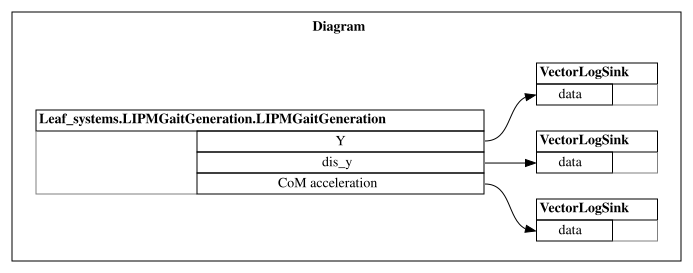

In [3]:
builder = DiagramBuilder()
z_com = 10.0
g = 9.807
# system = LIPMGaitGeneration(g = g, z_com = z_com-0.16)
system = LIPMGaitGeneration(g = g, z_com = z_com)
system = builder.AddSystem(system)

logger = LogVectorOutput(system.get_output_port(0), builder)
# logger2 = LogVectorOutput(dummy_system.get_output_port(0), builder)
disy_logger = LogVectorOutput(system.get_output_port(1), builder)
acc_logger = LogVectorOutput(system.get_output_port(2), builder)
diagram = builder.Build()
step_length = 0.1
start_swing = 0.03
y_0_offset = 0.0
y_0 = 0.125 + y_0_offset

step_time = 10.0
print(step_time, y_0, step_length)
[x_0, xd_0, y_0, yd_0, T_ss] = system.CalInitialCondition(step_time, y_0, step_length)

print("initial condition: ",[x_0, xd_0, y_0, yd_0, T_ss])
show_diagram(diagram=diagram,show=True)
simulator = Simulator(diagram)

In [4]:
# new_context = diagram.CreateDefaultContext()
# simulator.reset_context(new_context)
# # [x_0, xd_0, y_0, yd_0, T_ss] = system.CalInitialCondition(xd_mid, 0.0, step_length)
# # print([x_0, xd_0, y_0, yd_0, T_ss])
# new_context.SetContinuousState([x_0, xd_0, y_0, yd_0])
# # new_context.SetContinuousState([-0.1, 0.4, 0.35, -1.18])
# # new_context.SetContinuousState(system.CalInitialCondition(0.1, 0.35, 0.2)[0:4])
# # new_context.get_mutable_discrete_state_vector().SetFromVector([x_0, xd_0, -y_0, -yd_0])
# simulator.Initialize()
# simulator.AdvanceTo(T_ss)

# # Plot the results.
# log = logger.FindLog(new_context)
# dummy_log = logger.FindLog(new_context)
# dis_log = disy_logger.FindLog(new_context)
# plt.figure()
# plt.scatter(log.data()[0].transpose(), log.data()[2].transpose(),s=0.5,label='CoM position')
# # plt.plot(log.data()[0], log.data()[1].transpose())
# # plt.plot(log.sample_times(), log.data()[3].transpose())
# plt.title("LIP dynamics")
# plt.xlabel('x(t)')
# plt.ylabel('y(t)')
# plt.legend()
# # plt.axis('equal')
# plt.grid()
# plt.show()

### N steps

In [5]:
num_step = 1
CoM_x = np.array([])
CoM_y = np.array([])
CoM_xd = np.array([])
CoM_yd = np.array([])
CoM_xdd = np.array([])
CoM_ydd = np.array([])
foot_holdx = 0.0
foot_holdy = 0.0
foot_center = []

print([x_0, xd_0, y_0, yd_0, T_ss])
for i in range(num_step):
    new_context = diagram.CreateDefaultContext()
    simulator.reset_context(new_context)
    new_context.SetContinuousState([x_0, xd_0, y_0, yd_0])
    simulator.Initialize()
    simulator.AdvanceTo(T_ss-0.01)
    log = logger.FindLog(new_context)
    acc_log = acc_logger.FindLog(new_context)
    acc_data = acc_log.data()
    CoM_x = np.concatenate((CoM_x, log.data()[0]+foot_holdx))
    CoM_y = np.concatenate((CoM_y, log.data()[2]+foot_holdy))
    CoM_xd = np.concatenate((CoM_xd, log.data()[1]))
    CoM_yd = np.concatenate((CoM_yd, log.data()[3]))
    CoM_xdd = acc_data[0]
    CoM_ydd = acc_data[1]
    foot_holdx = foot_holdx + step_length
    foot_holdy = foot_holdy + 2.0*log.data()[2][-1]
    x_0 = x_0
    xd_0 = xd_0
    y_0 = -y_0
    yd_0 = -yd_0
    if i%2 == 0:
        temp = -0.018
    else:
        temp = 0.018 + L1*2
    foot_center.append((step_length*i + step_length*0.5+0.05, temp-L1))

CoM_y = CoM_y-y_0_offset

[-0.05, 0.049520103226614966, 0.125, np.float64(-0.123775489157416), 10.0]


In [6]:
acc_data.shape

(2, 1003)

In [7]:
print(CoM_xdd[0:4])

[ 0.         -0.04903014 -0.04900588 -0.04888483]


In [8]:
print(CoM_xd[0:4])

[0.0495201  0.0495152  0.04949069 0.04936833]


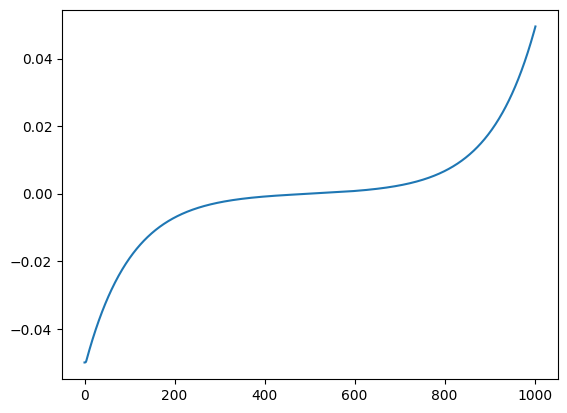

In [9]:
plt.plot(CoM_x)
plt.show()

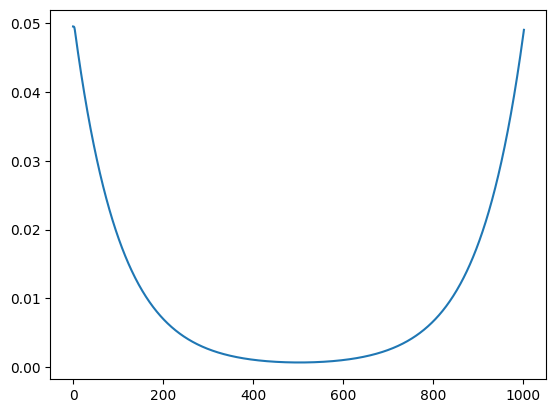

In [10]:
plt.plot(CoM_xd)
plt.show()

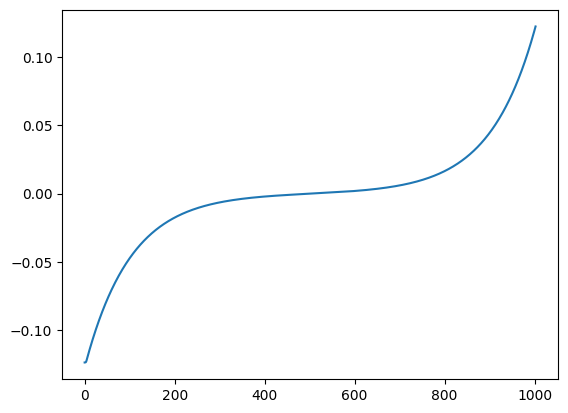

In [11]:
plt.plot(CoM_yd)
plt.show()

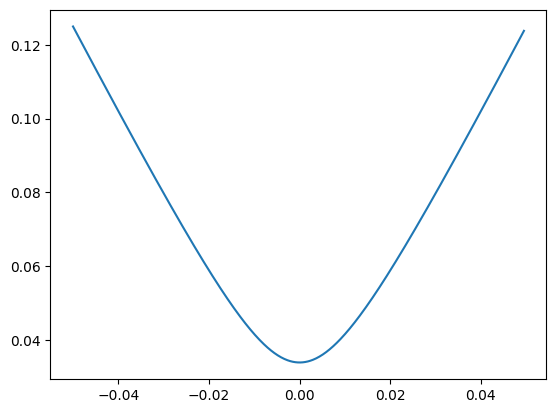

In [12]:
plt.plot(CoM_x,CoM_y)
plt.show()

In [6]:
walk_phase = []
for i in (CoM_y):
    if (i+y_0_offset < start_swing) or (i-y_0_offset > L1*2 - start_swing):
        walk_phase.append(0) # single support
    else:
        walk_phase.append(1) # double support
walk_phase = np.array(walk_phase) 
t_swing = np.count_nonzero(walk_phase == 0)*0.01/num_step
t0_swing = np.where(walk_phase == 0)[0][0]*0.01
print(len(walk_phase))
print(t_swing)
print(t0_swing)

503
4.51
0.28


In [7]:
import matplotlib.patches as patches
def DisplayGait (x_data, y_data, rectangle_centers, rectangle_size, description):
    """
    Plot a trajectory and rectangles in the same plot with equal resolution and a description below the plot.

    Parameters:
        x_data (list or array): X-axis data for the trajectory.
        y_data (list or array): Y-axis data for the trajectory.
        rectangle_centers (list of tuples): List of (x, y) coordinates for rectangle centers.
        rectangle_size (tuple): Size of rectangles (width, height).
        description (str): Description to display below the plot.

    Returns:
        None: Displays the plot.
    """
    # Create a figure and axis
    fig, ax = plt.subplots(figsize=(10, 8))

    # Plot the trajectory
    ax.scatter(x_data, y_data, label="CoM Trajectory", color="blue",s=0.1, linewidth=1)
    ax.plot(x_data,walk_phase*0.01)

    # Add rectangles
    for center in rectangle_centers:
        rect_x = center[0] - rectangle_size[0] / 2  # Bottom-left corner x
        rect_y = center[1] - rectangle_size[1] / 2  # Bottom-left corner y
        rectangle = patches.Rectangle(
            (rect_x, rect_y),  # Bottom-left corner
            rectangle_size[0],  # Width
            rectangle_size[1],  # Height
            edgecolor="red",  # Rectangle edge color
            facecolor="none",  # Transparent fill
            linewidth=2,
        )
        ax.add_patch(rectangle)

    # Set equal scaling for x and y axes
    ax.set_aspect("equal")

    # Set equal resolution by matching axis limits
    x_min, x_max = min(x_data) - 0.1, max(x_data) + 0.1
    y_min, y_max = min(y_data) - 0.1, max(y_data) + 0.1
    max_range = max(x_max - x_min, y_max - y_min)

    # Set tick steps to 0.1
    x_ticks = np.arange(x_min, x_max, 0.1)
    y_ticks = np.arange(-0.1, 0.15, 0.1)
    ax.set_xticks(x_ticks)
    ax.set_yticks(y_ticks)

    # Add description below the plot
    # fig.text(
    #     0.5, 0.32, description, ha="center", va="center", fontsize=12
    # )

    # Set plot labels and legend
    ax.set_xlabel('X [m]')
    ax.set_ylabel('Y [m]')
    ax.set_title('LIP CoM Trajectory : '+description)
    ax.legend()
    ax.grid(True)

    # Display the plot
    plt.show()

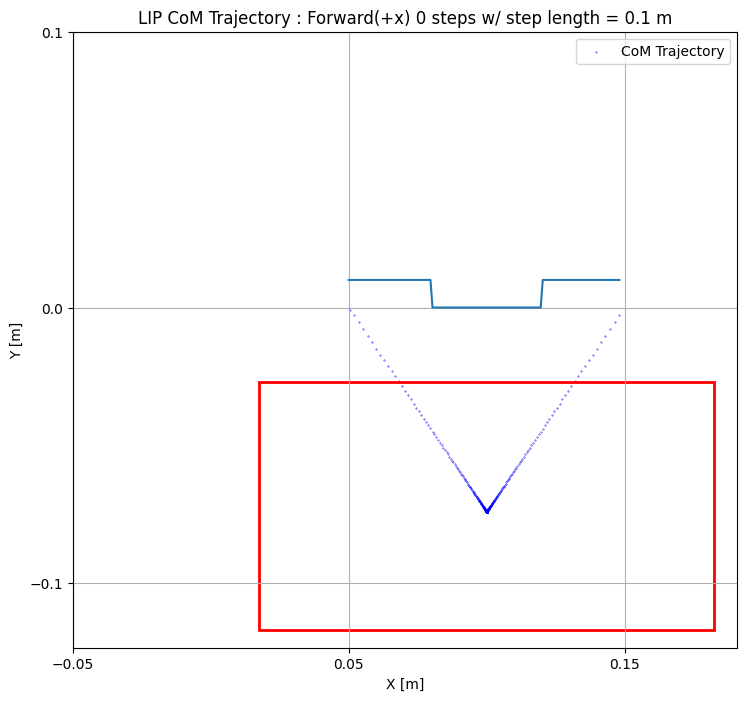

In [8]:
sole_size = (0.165, 0.09)  
# Plot the trajectory and rectangles
des = f"Forward(+x) {num_step-1} steps w/ step length = {step_length} m"
DisplayGait(CoM_x + step_length*0.5+0.05, CoM_y-L1, foot_center, sole_size,des)

In [9]:
# np.savez(f'com_data_{sample_name}.npz', CoM_x + step_length*0.5+0.05, CoM_y-L1, foot_center, sole_size,des)

### Test trajectory

In [10]:
from pydrake.all import (
    DiagramBuilder,
    LeafSystem,
    BasicVector,
    LinearSystem,
    Simulator
)
from pydrake.systems.primitives import LogVectorOutput
from volta.Leaf_systems.CubicTrajectory3D import CubicTrajectory3D

from volta.Leaf_systems.DummyParameters2 import DummyParameters2
from volta.utils import *

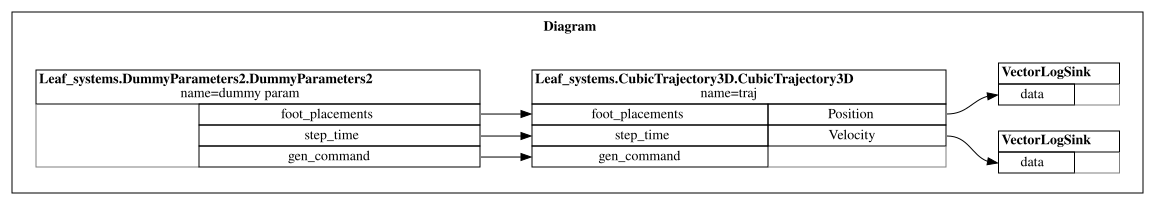

In [11]:
builder = DiagramBuilder()
dummy_system = builder.AddNamedSystem("dummy param",DummyParameters2(T0_swing=t0_swing,T_swing=t_swing,step_lenght=step_length))
traj = CubicTrajectory3D()
traj_system = builder.AddNamedSystem("traj",traj)
traj_system.z_max = 0.05

for i in range(3):
    builder.Connect(dummy_system.get_output_port(i),traj_system.get_input_port(i))
traj_logger = LogVectorOutput(traj_system.get_output_port(0), builder)
traj_vel_logger = LogVectorOutput(traj_system.get_output_port(1), builder) 
diagram = builder.Build()
show_diagram(diagram=diagram,show=True)


In [12]:
simulator = Simulator(diagram)
# Run the simulation.
context = diagram.CreateDefaultContext()
simulator.reset_context(context)
simulator.Initialize()
# simulator.set_target_realtime_rate(1.0)
simulator.AdvanceTo(round(T_ss,2))

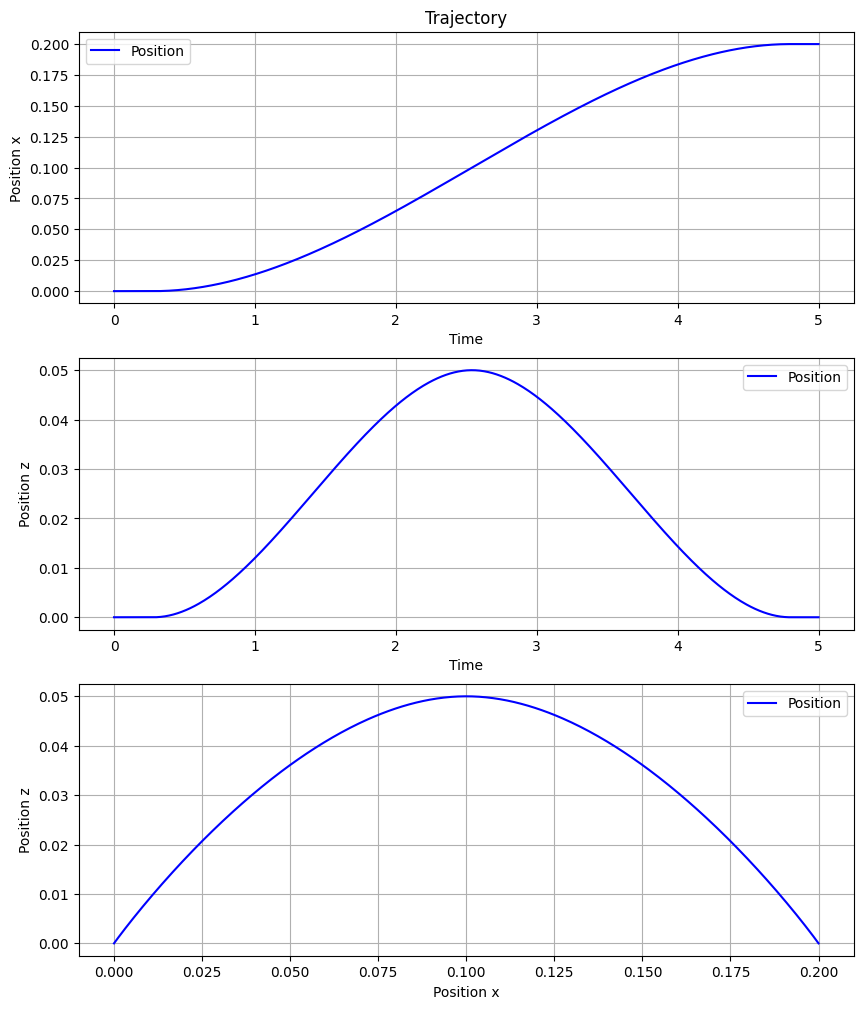

In [13]:
import matplotlib.pyplot as plt
times_to_evaluate = np.linspace(0, T_ss, int(T_ss*100))
log = traj_logger.FindLog(context)

plt.figure(figsize=(10, 12))
# Position plot
plt.subplot(3, 1, 1)
plt.plot(times_to_evaluate, log.data()[0][1:], label="Position", color='blue')
plt.title("Trajectory")
plt.ylabel("Position x")
plt.xlabel("Time")
plt.grid(True)
plt.legend()
plt.subplot(3, 1, 2)
plt.plot(times_to_evaluate, log.data()[2][1:], label="Position", color='blue')
# plt.title("Trajectory")
plt.ylabel("Position z")
plt.xlabel("Time")
plt.grid(True)
plt.legend()
plt.subplot(3, 1, 3)
plt.plot(log.data()[0][1:], log.data()[2][1:], label="Position", color='blue')
# plt.title("Trajectory")
plt.ylabel("Position z")
plt.xlabel("Position x")
plt.grid(True)
plt.legend()

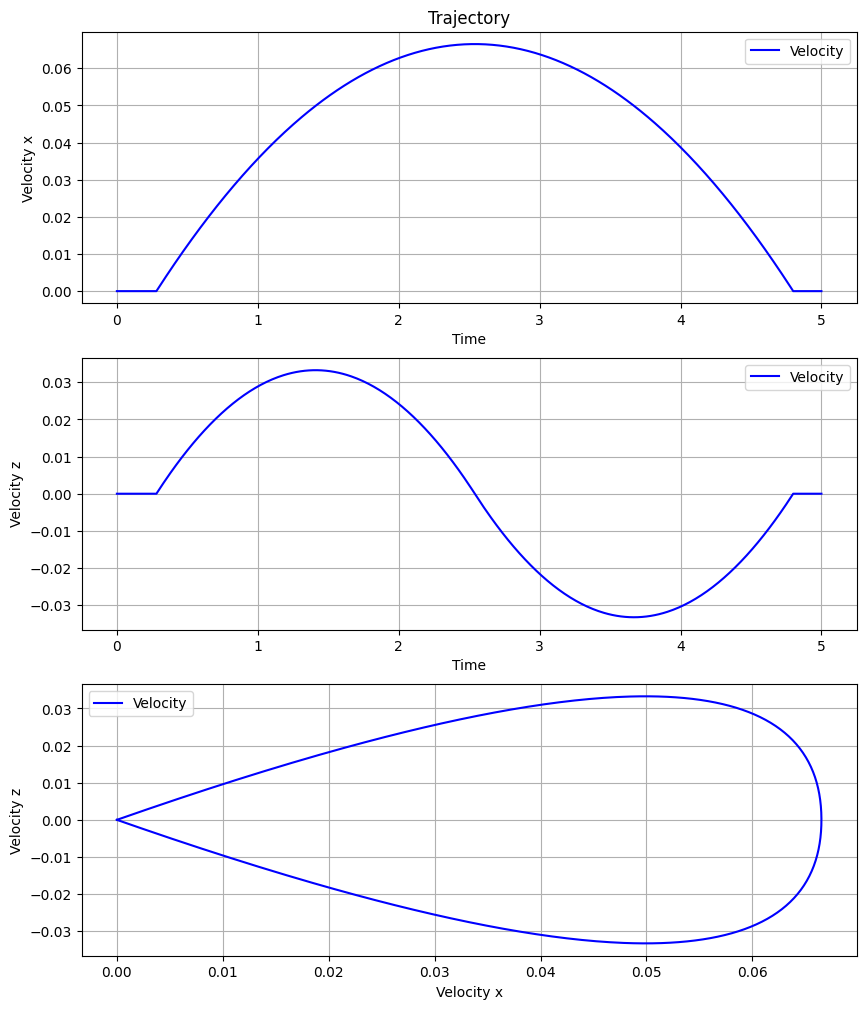

In [14]:
log_vel = traj_vel_logger.FindLog(context)

plt.figure(figsize=(10, 12))
# Position plot
plt.subplot(3, 1, 1)
plt.plot(times_to_evaluate, log_vel.data()[0][1:], label="Velocity", color='blue')
plt.title("Trajectory")
plt.ylabel("Velocity x")
plt.xlabel("Time")
plt.grid(True)
plt.legend()
plt.subplot(3, 1, 2)
plt.plot(times_to_evaluate, log_vel.data()[2][1:], label="Velocity", color='blue')
# plt.title("Trajectory")
plt.ylabel("Velocity z")
plt.xlabel("Time")
plt.grid(True)
plt.legend()
plt.subplot(3, 1, 3)
plt.plot(log_vel.data()[0][1:], log_vel.data()[2][1:], label="Velocity", color='blue')
# plt.title("Trajectory")
plt.ylabel("Velocity z")
plt.xlabel("Velocity x")
plt.grid(True)
plt.legend()

### IK

In [15]:
comX = np.delete(CoM_x, [1, 2, 3])
comY = np.delete(CoM_y, [1, 2, 3])
comZ = np.ones([comX.size])*(0.35)

# comX = CoM_x
# comY = CoM_y
# comXd = CoM_xd
# comYd = CoM_yd
# LIP_time = np.delete(log.sample_times(), [1, 2, 3])

st_P_c = np.array([comX,comY,comZ]).T

LIP_time = log.sample_times()
print(LIP_time.shape)
print(comX.shape)

(501,)
(500,)


In [16]:
swX = log.data()[0]
swY = log.data()[1]
swZ = log.data()[2]
sw0_P_sw = np.array([swX,swY,swZ]).T
print(sw0_P_sw.shape)
swXd = log_vel.data()[0]
swYd = log_vel.data()[1]
swZd = log_vel.data()[2]
sw0_V_sw = np.array([swXd,swYd,swZd]).T

comXd = np.delete(CoM_xd, [1, 2, 3])
comYd = np.delete(CoM_yd, [1, 2, 3])
comZd = np.zeros([comX.size])
st_V_c = np.array([comXd,comYd,comZd]).T

(501, 3)


In [17]:
LIP_time.size

501

In [18]:
st_P_c.shape

(500, 3)

In [19]:
st_P_sw0 = np.array([-step_length, L1*2.0, 0.0])
Q_L = []
Q_R = []
c_P_sw = []
c_P_st = []
c_V_sw = []
c_V_st = []
st_P_sw = []
actual_c_P_sw = []
actual_c_P_st = []
actual_st_P_sw = []

for ind in range(LIP_time.size - 1):
    st_R_c = RotationMatrix.MakeZRotation(-np.pi/2.0)   
    st_T_c = RigidTransform(st_R_c, st_P_c[ind])
    c_T_st = st_T_c.inverse()
    

    st_p_sw = st_P_sw0 + sw0_P_sw[ind]
    st_P_sw.append(st_p_sw)
    st_R_sw = RotationMatrix.MakeZRotation(0.0)
    st_T_sw = RigidTransform(st_R_sw, st_p_sw)

    c_T_sw = c_T_st @ st_T_sw
    R = RotationMatrix.MakeZRotation(np.pi/2.0) @ RotationMatrix.MakeYRotation(np.pi/2.0)
    th_L = CalcLegInverseKinematics(tform=RigidTransformToMatrix(RigidTransform(R ,c_T_sw.translation())),
                                    link_lengths=link_lengths,
                                    is_left=True)
    th_R = CalcLegInverseKinematics(tform=RigidTransformToMatrix(RigidTransform(R ,c_T_st.translation())),
                                    link_lengths=link_lengths,
                                    is_left=False)
    # th_L = SolveInverseKinematics(robot_name="Volta_rev4",
    #                               is_left=True,
    #                               base_P_e=c_T_sw.translation(),
    #                               base_R_e=c_T_sw.rotation())
    # th_R = SolveInverseKinematics(robot_name="Volta_rev4",
    #                               is_left=True,
    #                               base_P_e=c_T_st.translation(),
    #                               base_R_e=c_T_st.rotation())
    
    c_R_st = c_T_st.rotation()
    st_R_sw0 = RotationMatrix.MakeZRotation(0.0)
    c_v_st = c_R_st @ st_V_c[ind]
    c_v_st = -1.0*c_v_st
    c_v_sw = c_v_st + c_R_st @ st_R_sw0 @ sw0_V_sw[ind]

    # actual_c_T_sw = RigidTransform(c_T_sw.rotation(),actual_c_P_sw[0])
    # actual_st_T_sw = st_T_c @ actual_c_T_sw
    # actual_st_P_sw.append(actual_st_T_sw.translation())
    c_P_sw.append(c_T_sw.translation())
    c_P_st.append(c_T_st.translation())
    c_V_sw.append(c_v_sw)
    c_V_st.append(c_v_st)
    Q_L.append(th_L)
    Q_R.append(th_R)

st_P_sw = np.array(st_P_sw)
# actual_st_P_sw = np.array(actual_st_P_sw)
actual_c_P_sw = np.array(actual_c_P_sw)
actual_c_P_st = np.array(actual_c_P_st)
c_P_sw = np.array(c_P_sw)
c_P_st = np.array(c_P_st)
c_V_sw = np.array(c_V_sw)
c_V_st = np.array(c_V_st)


In [7]:
RotationMatrix.MakeZRotation(np.pi/2.0) 

RotationMatrix([
  [6.123233995736766e-17, -1.0, 0.0],
  [1.0, 6.123233995736766e-17, 0.0],
  [0.0, 0.0, 1.0],
])

In [20]:
q_L = np.array(Q_L)
q_R = np.array(Q_R)

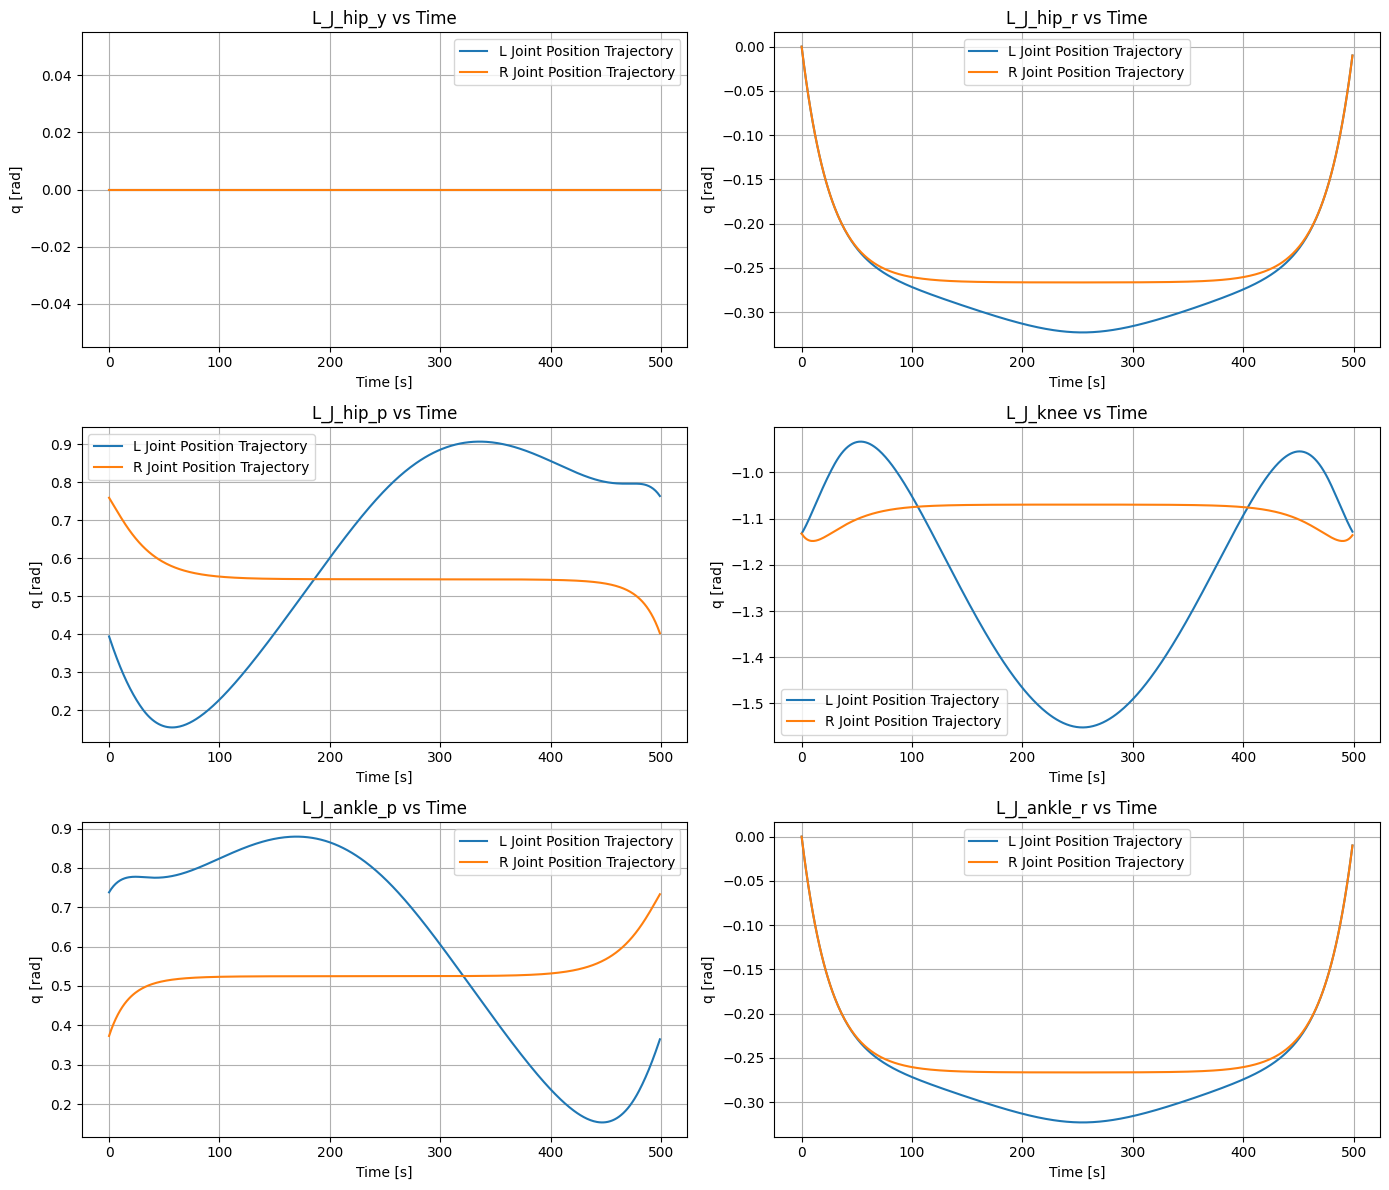

In [22]:
import matplotlib.pyplot as plt
name = ["J_hip_y","J_hip_r","J_hip_p","J_knee","J_ankle_p","J_ankle_r"]
fig, axs = plt.subplots(3, 2, figsize=(14, 12))
for i in range(6):
    temp = name[i]
    ax = axs[i // 2, i % 2]
    ax.plot(q_L[:,i], label="L Joint Position Trajectory")
    ax.plot(q_R[:,i], label="R Joint Position Trajectory")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("q [rad]")
    ax.set_title(f"L_{temp} vs Time")
    ax.legend()
    ax.grid()
plt.tight_layout()
plt.show()

### Save params

In [21]:
if save_to_file:
    params = np.array([T_ss,step_length,z_com,xd_mid,y_0_offset,start_swing,traj_system.z_max])
    file_name = f'q_data_{sample_name}.npz'
    path = f"/home/tanawat/Documents/Thesis/Thesis_simulation/Simulation/q_data/q_data_{sample_name}.npz"
    np.savez(path, q_L, q_R, c_P_sw, c_P_st, params)
    print(f"save to {file_name}")

In [22]:
# file_name = f'q_data_{sample_name}.npz'
# path = f"/home/tanawat/Documents/Thesis/Thesis_simulation/Simulation/q_data/task_space_data_{sample_name}.npz"
# np.savez(path, c_P_sw, c_V_sw, c_P_st, c_V_st)

### Plot

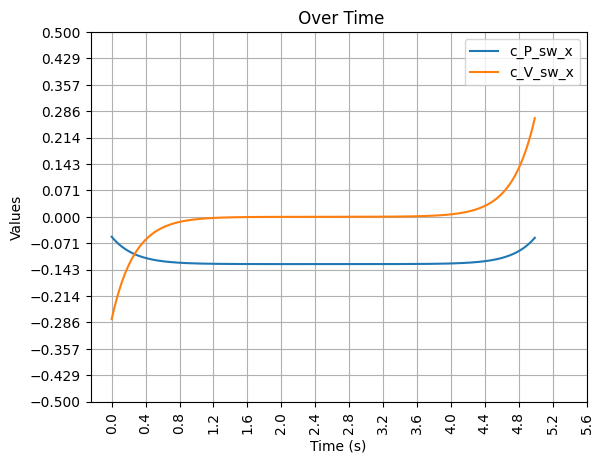

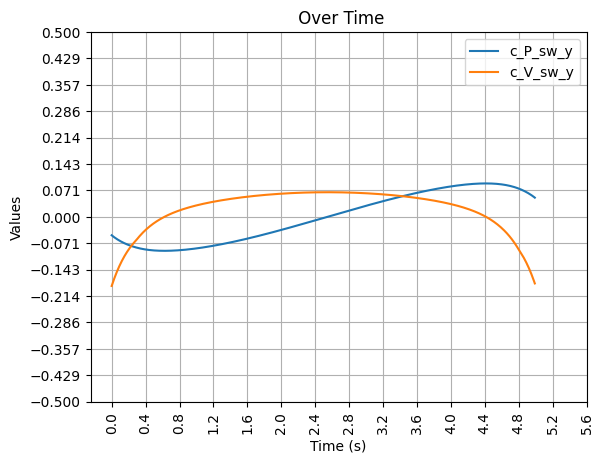

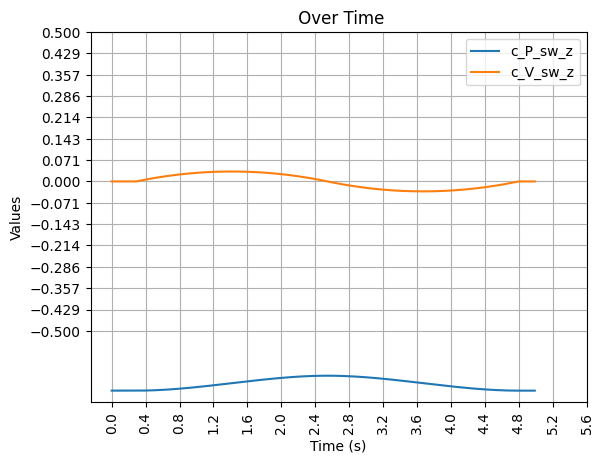

In [23]:
scale = 1.0
label = ["x","y","z"]
for i in range(3):
    plt.plot(LIP_time[0:-1], c_P_sw[:, i]*scale, label=f'c_P_sw_{label[i]}')
    plt.plot(LIP_time[0:-1], c_V_sw[:, i]*scale, label=f'c_V_sw_{label[i]}')
    # plt.plot(c_P_sw[:, i]*scale, label=f'c_P_sw_{label[i]}')
    # plt.plot(c_V_sw[:, i]*scale, label=f'c_V_sw_{label[i]}')
    # # Add labels and title
    plt.xlabel('Time (s)')  # Label for x-axis
    plt.ylabel('Values')    # Label for y-axis
    plt.title(' Over Time')  # Title for the graph
    x_res = np.linspace(0,56,15)
    plt.xticks(x_res*0.1,rotation ='vertical')  
    y_res = np.linspace(-5,5,15)
    plt.yticks(y_res*0.1) 
    # Add a legend
    plt.legend()
    plt.grid()
    plt.show()

In [24]:
# scale = 1.0
# label = ["x","y","z"]
# for i in range(3):
#     plt.plot(LIP_time, c_P_st[:, i]*scale, label=f'c_P_st_{label[i]}')
#     plt.plot(LIP_time, c_V_st[:, i]*scale, label=f'c_V_st_{label[i]}')
#     # # Add labels and title
#     plt.xlabel('Time (s)')  # Label for x-axis
#     plt.ylabel('Values')    # Label for y-axis
#     plt.title(' Over Time')  # Title for the graph
#     x_res = np.linspace(0,30,15)
#     plt.xticks(x_res*0.1,rotation ='vertical')  
#     y_res = np.linspace(-5,5,15)
#     plt.yticks(y_res*0.1) 
#     # Add a legend
#     plt.legend()
#     plt.grid()
#     plt.show()

IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

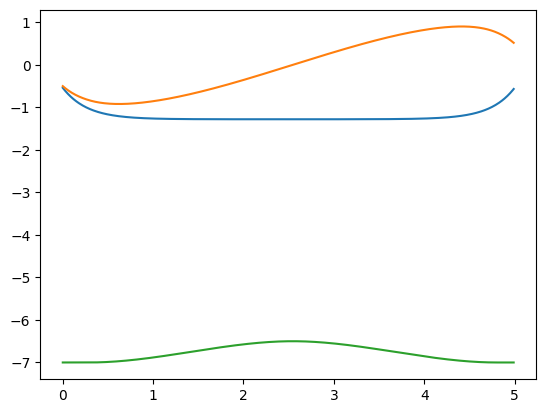

In [25]:
scale = 10.0
t = LIP_time[0:-1]
plt.plot(t, c_P_sw[:, 0]*scale, label='c_P_sw_x ')
plt.plot(t, c_P_sw[:, 1]*scale, label='c_P_sw_y')
plt.plot(t, c_P_sw[:, 2]*scale, label='c_P_sw_z')
plt.plot(t, actual_c_P_sw[:, 0]*scale, label='actual_c_P_sw_x ')
plt.plot(t, actual_c_P_sw[:, 1]*scale, label='actual_c_P_sw_y')
plt.plot(t, actual_c_P_sw[:, 2]*scale, label='actual_c_P_sw_z')
# # Add labels and title
plt.xlabel('Time (s)')  # Label for x-axis
plt.ylabel('Values')    # Label for y-axis
plt.title('q Over Time')  # Title for the graph
x_res = np.linspace(0,int(T_ss*10),15)
plt.xticks(x_res*0.1,rotation ='vertical')  
y_res = np.linspace(-30,15,15)
plt.yticks(y_res*0.1) 
# Add a legend
plt.legend()
plt.grid()
plt.show()

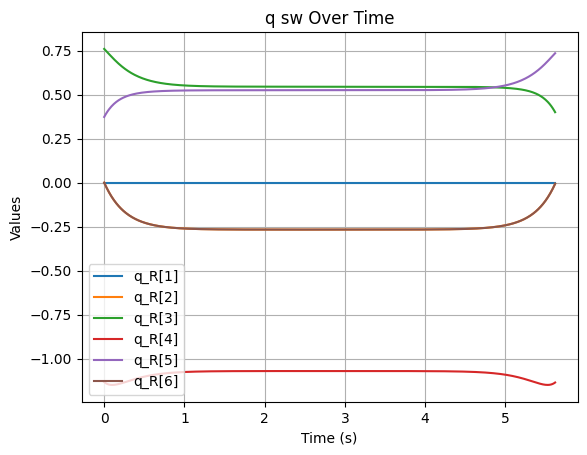

In [ ]:
plt.plot(t, q_R[:, 0], label='q_R[1]')
plt.plot(t, q_R[:, 1], label='q_R[2]')
plt.plot(t, q_R[:, 2], label='q_R[3]')
plt.plot(t, q_R[:, 3], label='q_R[4]')
plt.plot(t, q_R[:, 4], label='q_R[5]')
plt.plot(t, q_R[:, 5], label='q_R[6]')


# Add labels and title
plt.xlabel('Time (s)')  # Label for x-axis
plt.ylabel('Values')    # Label for y-axis
plt.title('q sw Over Time')  # Title for the graph
# x_res = np.linspace(0,int(T_ss*10),15)
# plt.xticks(x_res*0.1,rotation ='vertical')  
# y_res = np.linspace(-30,15,15)
# plt.yticks(y_res*0.1) 
# Add a legend
plt.legend()
plt.grid()
plt.show()

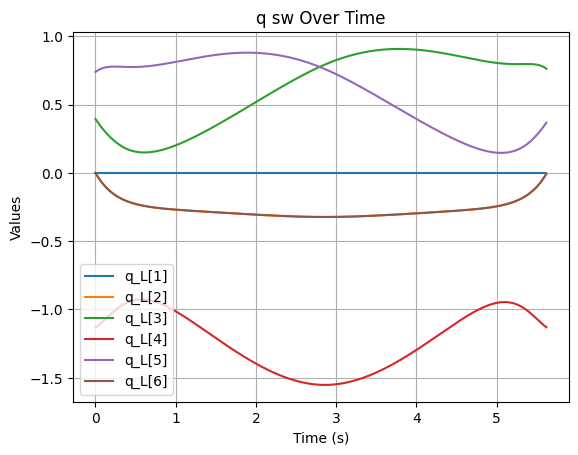

In [ ]:
plt.plot(t, q_L[:, 0], label='q_L[1]')
plt.plot(t, q_L[:, 1], label='q_L[2]')
plt.plot(t, q_L[:, 2], label='q_L[3]')
plt.plot(t, q_L[:, 3], label='q_L[4]')
plt.plot(t, q_L[:, 4], label='q_L[5]')
plt.plot(t, q_L[:, 5], label='q_L[6]')


# Add labels and title
plt.xlabel('Time (s)')  # Label for x-axis
plt.ylabel('Values')    # Label for y-axis
plt.title('q sw Over Time')  # Title for the graph
# x_res = np.linspace(0,int(T_ss*10),15)
# plt.xticks(x_res*0.1,rotation ='vertical')  
# y_res = np.linspace(-30,15,15)
# plt.yticks(y_res*0.1) 
# Add a legend
plt.legend()
plt.grid()
plt.show()

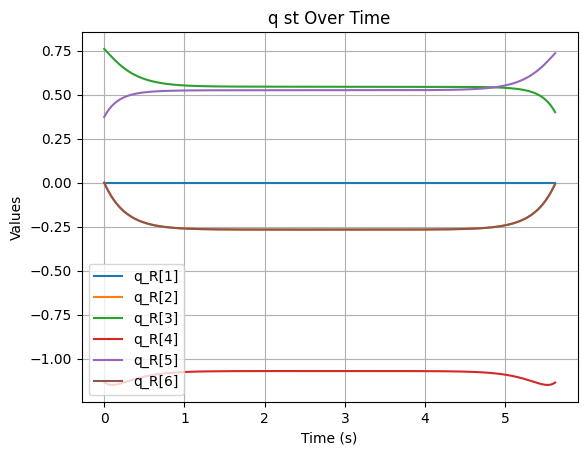

In [ ]:

plt.plot(t, q_R[:, 0], label='q_R[1]')
plt.plot(t, q_R[:, 1], label='q_R[2]')
plt.plot(t, q_R[:, 2], label='q_R[3]')
plt.plot(t, q_R[:, 3], label='q_R[4]')
plt.plot(t, q_R[:, 4], label='q_R[5]')
plt.plot(t, q_R[:, 5], label='q_R[6]')


# Add labels and title
plt.xlabel('Time (s)')  # Label for x-axis
plt.ylabel('Values')    # Label for y-axis
plt.title('q st Over Time')  # Title for the graph
# x_res = np.linspace(0,int(T_ss*10),15)
# plt.xticks(x_res*0.1,rotation ='vertical')  
# y_res = np.linspace(-30,15,15)
# plt.yticks(y_res*0.1) 
# Add a legend
plt.legend()
plt.grid()
plt.show()

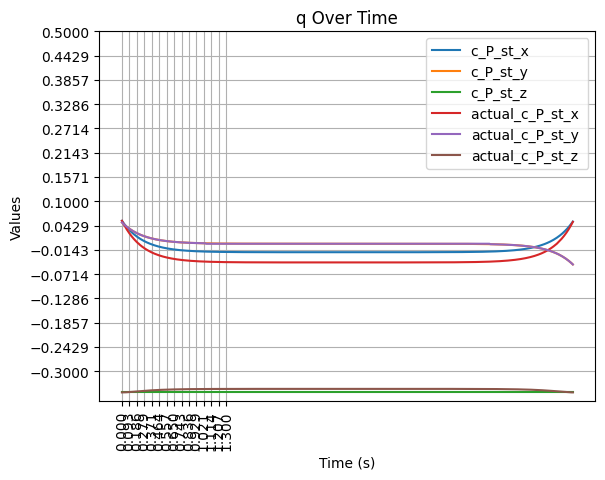

In [ ]:
scale = 1.0
plt.plot(t, c_P_st[:, 0]*scale, label='c_P_st_x ')
plt.plot(t, c_P_st[:, 1]*scale, label='c_P_st_y')
plt.plot(t, c_P_st[:, 2]*scale, label='c_P_st_z')
plt.plot(t, actual_c_P_st[:, 0]*scale, label='actual_c_P_st_x ')
plt.plot(t, actual_c_P_st[:, 1]*scale, label='actual_c_P_st_y')
plt.plot(t, actual_c_P_st[:, 2]*scale, label='actual_c_P_st_z')
# # Add labels and title
plt.xlabel('Time (s)')  # Label for x-axis
plt.ylabel('Values')    # Label for y-axis
plt.title('q Over Time')  # Title for the graph
x_res = np.linspace(0,13,15)
plt.xticks(x_res*0.1,rotation ='vertical')  
y_res = np.linspace(-3,5,15)
plt.yticks(y_res*0.1) 
# Add a legend
plt.legend()
plt.grid()
plt.show()

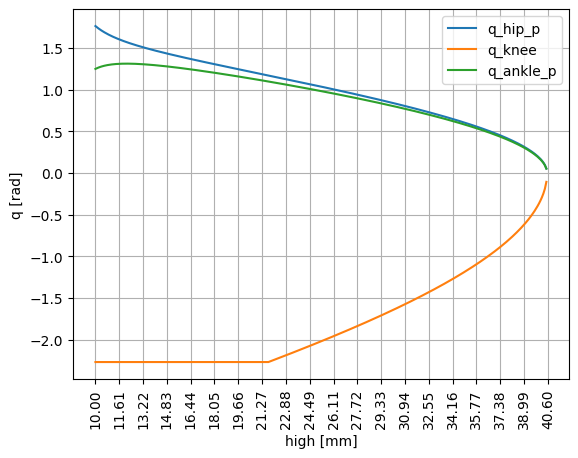

In [ ]:
body_high = 0.1
min = 0.1
q = []
x = []
# L1 = 0.049
# L2 = 0
# L3 = 0.155
# L4 = 0.155
# L5 = 0.0335
# link_lengths = [L1,L2,L3,L4,L5]
while body_high < 0.4055:
    hip_high  = body_high
    body_R_Lfoot = np.array([
                            [0,-1, 0],
                            [0, 0, 1],
                            [-1,0, 0],
                            [0, 0, 0]])
    body_P_Lfoot = np.array([[-0.049, 0.0, -hip_high, 1]]).T
    body_T_Lfoot = np.concatenate((body_R_Lfoot,body_P_Lfoot),axis=1)
    th = CalcLegInverseKinematics(tform=body_T_Lfoot,
                                    link_lengths=link_lengths,
                                    is_left=True)
    out_of_bound, th = CheckJointLimits(joint_angles=th)
    for i in range(6):
        if abs(th[i]) < 0.00000001:
            th[i] = 0.0

    q.append(th)
    x.append(body_high)
    body_high += 0.001

x = np.array(x)  
q = np.array(q).T
name = ["hip_p","knee","ankle_p"]
for i in [2,3,4]:
    l = f"q_{name[i-2]}"
    plt.plot(x*100,q[i,:],label = l)
    plt.xlabel("high [mm]")
    plt.ylabel("q [rad]")
x_res = np.linspace(min*100,body_high*100,20)
plt.xticks(x_res,rotation ='vertical')  # X-axis resolution
# plt.yticks(np.arange(-2.5, 1.1, 1.5))  # Y-axis resolution (assuming values range from 0 to 1)

# Enable grid with specific line style and transparency
# plt.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)
plt.legend()
plt.grid()
plt.show()
